# k-Nearest Neighbours

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hamedheli/ml-from-scratch/blob/main/01-k-nearest-neighbours/knn.ipynb) [![View in nbviewer](https://img.shields.io/badge/view%20in-nbviewer-orange)](https://nbviewer.org/github/HamedHeli/ml-from-scratch/blob/main/01-k-nearest-neighbours/knn.ipynb)

Part of [Machine Learning From Scratch](../README.md). The code for this model is in this folder; shared helpers (data loading, plotting, loss functions) are in [`common/`](../common).


## Setup

In [1]:
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    # On Colab, get the code and data from GitHub first
    if not Path("/content/ml-from-scratch").exists():
        !git clone -q https://github.com/hamedheli/ml-from-scratch.git /content/ml-from-scratch
    ROOT = Path("/content/ml-from-scratch")
else:
    ROOT = Path.cwd().resolve().parent  # this notebook sits in one model folder

# shared helpers, plus the model folders this notebook uses
for folder in ["common", "01-k-nearest-neighbours", "02-decision-trees"]:
    sys.path.insert(0, str(ROOT / folder))


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from utils import load_dataset, plot_classifier, euclidean_dist_squared, mode
from knn import KNN
from decision_tree import DecisionTree  # only for the comparison in 1.4

plt.rcParams["figure.figsize"] = (7, 5)
np.random.seed(0)  # makes the random initializations (and the numbers quoted below) reproducible


k-NN has no real training step: `fit` just stores the data. To classify a new point, it finds the $k$ closest training points and returns their most common label. Small $k$ gives a flexible decision boundary that follows the noise in the training set (low bias, high variance). Large $k$ averages over more neighbours and gives a smoother boundary (higher bias, lower variance).

**What I implemented**
* `KNN` in [`knn.py`](knn.py) with `fit` and `predict`.
* `euclidean_dist_squared` in [`utils.py`](../common/utils.py), which computes all test-to-train distances in one matrix operation using $\|a-b\|^2 = \|a\|^2 + \|b\|^2 - 2a^\top b$ instead of a double loop.
* 10-fold cross-validation, written by hand below, to choose $k$.

Models are compared by accuracy, or by its complement, the classification error $\frac{1}{n}\sum_{i=1}^{n}\mathbb{1}[\hat y_i \neq y_i]$.

**Data**
* `citiesSmall`: 400 training and 2,000 test US cities. The two features are longitude and latitude, and the label is a binary political alignment. Source: [SimpleMaps US Cities](https://simplemaps.com/data/us-cities).
* `ccdebt`: 2,000 training and 500 test households with 91 demographic and financial features, and a binary label about consumer debt. Source: [Statistics Canada, Survey of Financial Security](https://open.canada.ca/data/en/dataset/11aecdcb-8bec-4dbe-9da2-3b0cc4e740c9).

## 1. Load the data

In [3]:
dataset = load_dataset("citiesSmall.pkl")
X = dataset["X"]
print(f"The shape of features in citiesSmall is {X.shape}")


dataset = load_dataset("ccdebt.pkl")
X = dataset["X"]
print(f"The shape of features in ccdebt is {X.shape}")

The shape of features in citiesSmall is (400, 2)
The shape of features in ccdebt is (2000, 91)


## 2. Prediction
This is the `predict` method from `knn.py`, repeated here so the core logic is visible. `D_squared` is a $t \times n$ matrix with one row per test point. Sorting each row gives the indices of the nearest training points, and the prediction is the mode of their labels.

In [4]:
def predict(self, X_hat):
    t = X_hat.shape[0]
    y_hat = np.zeros(t)

    # Compute squared Euclidean distances between X_hat and training data X
    D_squared = euclidean_dist_squared(X_hat, self.X)

    # Find the indices of the k nearest neighbors
    neigh_idx = D_squared.argsort(axis=1)[:, :self.k]

    for i in range(t):
        # Use mode to handle ties
        y_hat[i] = mode(self.y[neigh_idx[i,:]])

    return y_hat

## 3. Choosing $k$ with cross-validation
For each $k$, the 400 training cities are split into 10 folds. The model is trained on 9 folds and scored on the held-out fold, and the 10 scores are averaged. The 2,000 test cities are used only to check that cross-validation picks a sensible $k$.

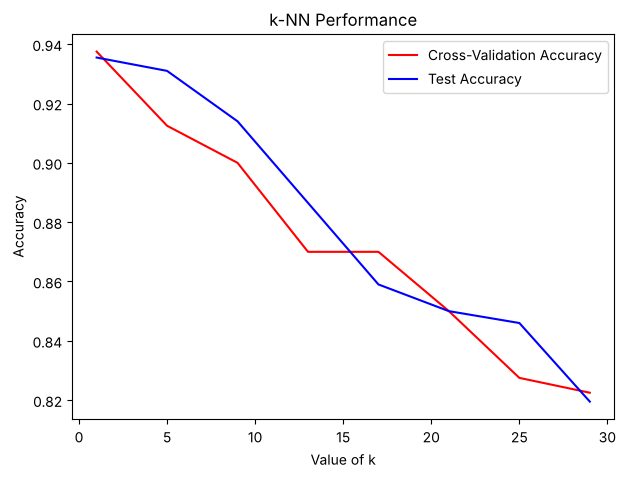

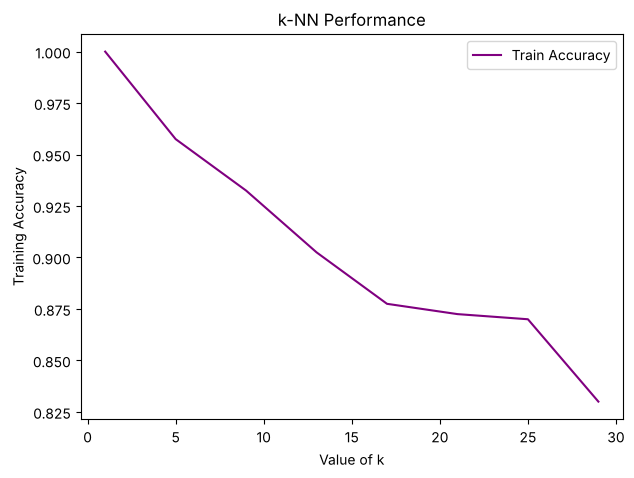

In [5]:
def accuracy_vs_k():
    dataset = load_dataset("citiesSmall.pkl")
    X = dataset["X"]
    y = dataset["y"]
    X_test = dataset["Xtest"]
    y_test = dataset["ytest"]
    n,d = X.shape
    ks = list(range(1, 30, 4))
    fold_n = 10
    fold_size = n//fold_n
    accuracy = np.zeros((fold_n, len(ks)))
    test_accs = np.zeros(len(ks))
    train_accs = np.zeros(len(ks))

    for k_idx in range(len(ks)):
        for fold_idx in range(10):
            mask = np.ones(n, dtype=bool)   # reset mask
            mask [fold_idx*fold_size:(fold_idx+1)*fold_size] = False
            X_fold_train = X[mask,:]
            y_fold_train = y[mask]
            X_fold_test = X[~mask,:]
            y_fold_test = y[~mask]
            knn = KNN(ks[k_idx])
            knn.fit(X_fold_train,y_fold_train)
            y_fold_hat = knn.predict(X_fold_test)
            accuracy[fold_idx, k_idx] = np.mean(y_fold_hat == y_fold_test)
        knn = KNN(ks[k_idx])
        knn.fit(X,y)
        y_hat = knn.predict(X_test)
        y_hat_train = knn.predict(X)
        test_accs[k_idx] = np.mean(y_hat == y_test)
        train_accs[k_idx] = np.mean(y_hat_train == y)
            ## accuracy is a matrix with columns be each k (for KNN) and the rows are each fold (10-fold)
    cv_accs =  np.mean(accuracy, axis = 0)
    plt.plot(ks, cv_accs, linestyle = '-', color = 'red', label='Cross-Validation Accuracy')
    plt.plot(ks, test_accs, linestyle = '-', color = 'blue', label='Test Accuracy')
    plt.xlabel("Value of k")
    plt.ylabel("Accuracy")
    plt.title("k-NN Performance")
    plt.legend()
    plt.show()


    plt.plot(ks, train_accs, linestyle = '-', color = 'purple', label='Train Accuracy')
    plt.xlabel("Value of k")
    plt.ylabel("Training Accuracy")
    plt.title("k-NN Performance")
    plt.legend()
    plt.show()

accuracy_vs_k()

Cross-validation accuracy tracks test accuracy closely, and both are highest at $k=1$. Training accuracy is 100% at $k=1$, because every point is its own nearest neighbour, and it falls as $k$ grows. The two classes form compact regions on the map, so a very local model works well here.

## 4. k-NN vs. a decision tree
The same data, compared with the depth-5 decision tree from [Decision Trees](../02-decision-trees/decision_trees.ipynb):

In [6]:
def knn_vs_tree():
    dataset = load_dataset("citiesSmall.pkl")
    X = dataset["X"]
    y = dataset["y"]
    X_test = dataset["Xtest"]
    y_test = dataset["ytest"]

    print(f"{'Model':<25}{'Train error':>12}{'Test error':>12}")
    for k in [1, 3, 10]:
        knn = KNN(k)
        knn.fit(X, y)
        error_knn_train = 1 - np.mean(knn.predict(X) == y)
        error_knn_test = 1 - np.mean(knn.predict(X_test) == y_test)
        print(f"{f'k-NN (k={k})':<25}{error_knn_train*100:>11.1f}%{error_knn_test*100:>11.1f}%")

    tree = DecisionTree(5)
    tree.fit(X,y)
    y_hat_tree_train = tree.predict(X)
    error_tree_train = 1- np.mean(y_hat_tree_train == y)
    y_hat_tree_test = tree.predict(X_test)
    error_tree_test = 1- np.mean(y_hat_tree_test == y_test)
    print(f"{'Decision tree (depth=5)':<25}{error_tree_train*100:>11.1f}%{error_tree_test*100:>11.1f}%")

knn_vs_tree()

Model                     Train error  Test error
k-NN (k=1)                       0.0%        6.5%
k-NN (k=3)                       2.7%        6.6%
k-NN (k=10)                      5.8%        8.5%


Decision tree (depth=5)         10.8%       16.1%


k-NN has less than half the test error of the tree. Each tree split is a single threshold on one feature, so the tree can only carve the map into axis-aligned rectangles, and the diagonal, irregular borders between the regions are hard to approximate that way. k-NN has no such restriction. The $k=1$ boundary below shows this. It also shows small islands around individual points, which is what overfitting to single examples looks like.

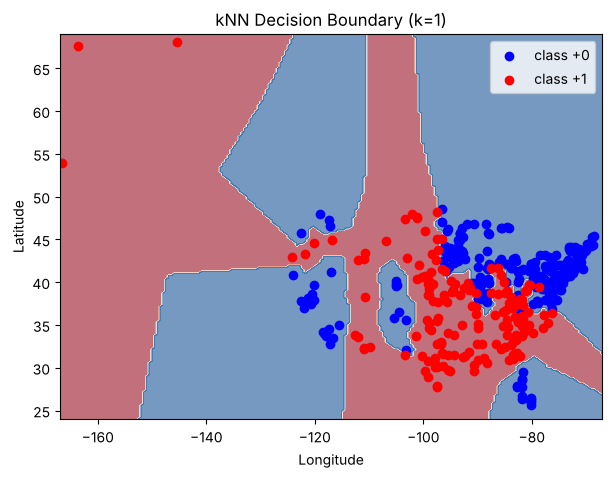

In [7]:
dataset = load_dataset("citiesSmall.pkl")
X, y = dataset["X"], dataset["y"]

model = KNN(k=1)
model.fit(X, y)

plot_classifier(model, X, y)
plt.title("kNN Decision Boundary (k=1)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

## 5. Cross-validation on a harder dataset
The household debt data has 91 features and much noisier labels. The 10-fold procedure is the same. This time the test accuracy is also recorded for each $k$, so the two can be compared.

In [8]:
def cross_validate_knn():
    dataset = load_dataset("ccdebt.pkl")
    X, y = dataset["X"], dataset["y"]
    X_test, y_test = dataset["Xtest"], dataset["ytest"]
    n, d = X.shape
    ks = list(range(1, 30, 4))
    fold_n = 10
    fold_size = n // fold_n

    accuracy = np.zeros((fold_n, len(ks)))
    test_accs = np.zeros(len(ks))

    for k_idx, k in enumerate(ks):
        for fold in range(fold_n):
            mask = np.ones(n, dtype=bool)
            mask[fold*fold_size : (fold+1)*fold_size] = False

            X_train, y_train = X[mask], y[mask]
            X_val, y_val = X[~mask], y[~mask]

            knn = KNN(k)
            knn.fit(X_train, y_train)
            y_pred = knn.predict(X_val)
            accuracy[fold, k_idx] = np.mean(y_pred == y_val)

        knn = KNN(k)
        knn.fit(X, y)
        test_accs[k_idx] = np.mean(knn.predict(X_test) == y_test)

    cv_accs = np.mean(accuracy, axis=0)
    return ks, cv_accs, test_accs

ks, cv_accs, test_accs = cross_validate_knn()
print(f"Best k found by CV: {ks[np.argmax(cv_accs)]}")

Best k found by CV: 17


## 6. Cross-validation vs. test accuracy

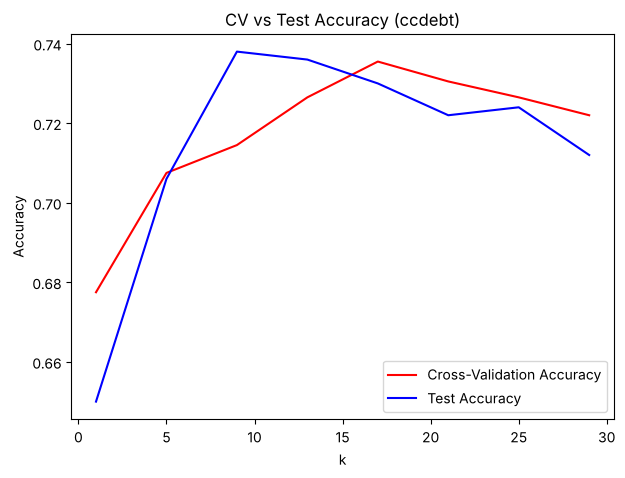

In [9]:
plt.plot(ks, cv_accs, label="Cross-Validation Accuracy", color='red')
plt.plot(ks, test_accs, label="Test Accuracy", color='blue')
plt.xlabel("k")
plt.ylabel("Accuracy")
plt.legend()
plt.title("CV vs Test Accuracy (ccdebt)")
plt.show()

Here $k=1$ is clearly the worst choice (65% test accuracy). With noisy labels, copying a single neighbour copies its noise. Test accuracy peaks around $k = 9$ to $17$. Cross-validation picks $k=17$ (73.0% test accuracy), within one percentage point of the best test accuracy of 73.8% at $k=9$, without ever looking at the test set. For context, always predicting the majority class gets 67.8% on the test set, so k-NN improves on that by about 5 to 6 points. Distances between raw 91-dimensional feature vectors only capture part of the signal in this data.